# 02 - Feature engineering, model training and MLflow tracking
Three model families are tuned with 5-fold stratified grid search on 80% of the data. The best one by mean CV ROC-AUC becomes the champion. The 20% hold-out set is only used for the final report numbers.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 140)

## Preprocessing pipeline
Engineered feature `hr_reserve_pct = thalach / (220 - age)` (share of age-predicted max heart rate). Numeric: median impute + standard scale. Binary: most-frequent impute. Categorical (`cp`, `restecg`, `slope`, `thal`): most-frequent impute + one-hot.

In [2]:
from heartrisk.features import build_preprocessor, split_xy
from heartrisk import data
X, y = split_xy(data.load_clean())
pre = build_preprocessor().fit(X)
names = pre.named_steps['columns'].get_feature_names_out()
print(len(names), 'model features:'); print(list(names))

23 model features:
['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca', 'hr_reserve_pct', 'sex', 'fbs', 'exang', 'cp_1.0', 'cp_2.0', 'cp_3.0', 'cp_4.0', 'restecg_0.0', 'restecg_1.0', 'restecg_2.0', 'slope_1.0', 'slope_2.0', 'slope_3.0', 'thal_3.0', 'thal_6.0', 'thal_7.0']


## Train all candidates (logged to MLflow)

In [3]:
from heartrisk.train import train, candidates
for k, (est, grid) in candidates().items():
    print(k, {p.replace('model__',''): v for p, v in grid.items()})

logistic_regression {'C': [0.01, 0.1, 0.3, 1.0, 3.0], 'penalty': ['l1', 'l2'], 'class_weight': [None, 'balanced']}
random_forest {'n_estimators': [200, 400], 'max_depth': [3, 5, None], 'min_samples_leaf': [1, 3, 5], 'max_features': ['sqrt', 0.5]}
gradient_boosting {'n_estimators': [100, 200], 'learning_rate': [0.03, 0.1], 'max_depth': [2, 3], 'subsample': [0.8, 1.0]}


In [4]:
meta = train()

2026/10/09 07:16:50 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/09 07:16:50 INFO mlflow.store.db.utils: Updating database tables


2026-10-09 07:16:50 INFO  [alembic.runtime.migration] Context impl SQLiteImpl.


2026-10-09 07:16:50 INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


2026-10-09 07:16:50 INFO  [alembic.runtime.migration] Running upgrade  -> 451aebb31d03, add metric step


...

2026/10/09 07:18:13 INFO mlflow.store.db.utils: Updating database tables


2026-10-09 07:18:13 INFO  [alembic.runtime.migration] Context impl SQLiteImpl.


2026-10-09 07:18:13 INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


                     cv_accuracy  cv_precision  cv_recall   cv_f1  cv_roc_auc  cv_roc_auc_std  cv_recall_std  test_accuracy  test_precision  test_recall  test_f1  test_roc_auc  threshold
logistic_regression       0.8552        0.8819     0.8008  0.8342      0.9071          0.0202         0.0750         0.8033          0.7105       0.9643   0.8182        0.9610       0.30
random_forest             0.8181        0.8387     0.7644  0.7916      0.8996          0.0234         0.0983         0.7869          0.6923       0.9643   0.8060        0.9535       0.31
gradient_boosting         0.8180        0.8358     0.7648  0.7928      0.8835          0.0245         0.0797         0.7377          0.6429       0.9643   0.7714        0.9578       0.22


Successfully registered model 'heart-disease-classifier'.
Created version '1' of model 'heart-disease-classifier'.


In [5]:
cmp = pd.read_csv('reports/model_comparison.csv', index_col=0)
cmp[['cv_roc_auc','cv_accuracy','cv_precision','cv_recall','test_roc_auc','test_accuracy','test_precision','test_recall','threshold']]

,cv_roc_auc,cv_accuracy,cv_precision,cv_recall,test_roc_auc,test_accuracy,test_precision,test_recall,threshold
logistic_regression,0.9071,0.8552,0.8819,0.8008,0.9610,0.8033,0.7105,0.9643,0.30
random_forest,0.8996,0.8181,0.8387,0.7644,0.9535,0.7869,0.6923,0.9643,0.31
gradient_boosting,0.8835,0.8180,0.8358,0.7648,0.9578,0.7377,0.6429,0.9643,0.22


## Decision threshold
For a screening tool a missed patient (false negative) is worse than a false alarm. The threshold is chosen from out-of-fold training predictions as the highest value that still gives >= 90% recall, then applied unchanged to the hold-out set.

In [6]:
import json; print(json.dumps(meta, indent=2, default=str))

{
  "model_name": "logistic_regression",
  "model_version": "1.0.0+31a61fa",
  "registry_name": "heart-disease-classifier",
  "registry_version": 1,
  "mlflow_run_id": "6aacdd7c9fc745c1827f41ee11c4ec8f",
  "decision_threshold": 0.3,
  "target_recall": 0.9,
  "best_params": {
    "C": 0.3,
    "class_weight": "balanced",
    "penalty": "l2"
  },
  "metrics": {
    "cv_accuracy": 0.8552,
    "cv_precision": 0.8819,
    "cv_recall": 0.8008,
    "cv_f1": 0.8342,
    "cv_roc_auc": 0.9071,
    "cv_roc_auc_std": 0.0202,
    "cv_recall_std": 0.075,
    "test_accuracy": 0.8033,
    "test_precision": 0.7105,
    "test_recall": 0.9643,
    "test_f1": 0.8182,
    "test_roc_auc": 0.961
  },
  "features": [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal"
  ],
  "trained_at": "2026-10-09T07:18:13+00:00",
  "sklearn_version": "1.7.2",
  "python_version": "3.11.17"
}


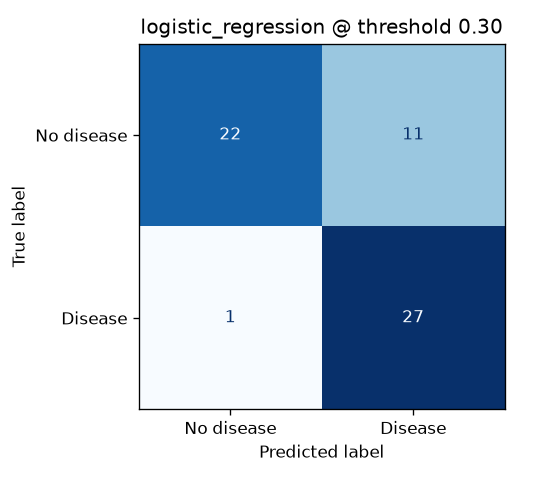

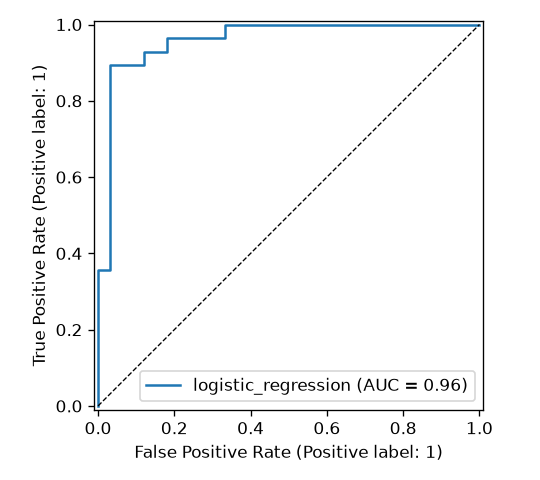

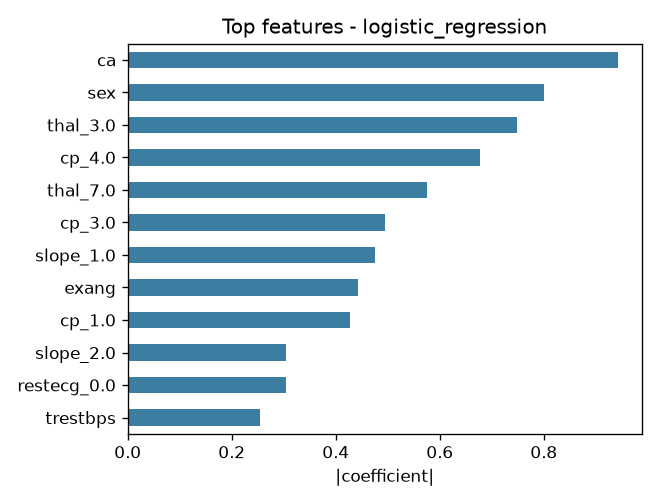

In [7]:
m = meta['model_name']
for f in [f'confusion_matrix_{m}.png', f'roc_curve_{m}.png', f'feature_importance_{m}.png']:
    display(Image(f'reports/figures/{f}'))

## Browse the runs
```
mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5001
```
then open http://localhost:5001 -> experiment `heart-disease-risk`.

In [8]:
import mlflow
mlflow.set_tracking_uri(f'sqlite:///{ROOT}/mlflow.db')
runs = mlflow.search_runs(experiment_names=['heart-disease-risk'])
runs[['tags.mlflow.runName','metrics.cv_roc_auc','metrics.test_roc_auc','metrics.test_recall','params.decision_threshold','start_time']].head(10)

,tags.mlflow.runName,metrics.cv_roc_auc,metrics.test_roc_auc,metrics.test_recall,params.decision_threshold,start_time
0,gradient_boosting,0.883490,0.957792,0.964286,0.22,2026-10-09 07:18:01.329000+00:00
1,random_forest,0.899582,0.953463,0.964286,0.31,2026-10-09 07:16:59.208000+00:00
2,logistic_regression,0.907131,0.961039,0.964286,0.3,2026-10-09 07:16:51.334000+00:00
